# Newton continuation of a periodic orbit

In [342]:
"""Continue the known high-energy periodic orbit to lower energies.

For each fixed energy E:
    P_E(z) = next return to y1=5 with py1>0
    Newton solves P_E(z) - z = 0
    eig(DP_E(z*)) gives the Floquet multipliers
"""

import numpy as np
import matplotlib.pyplot as plt

from system import System, inverse_power_potential, kinetic

## system and known high-energy orbit

In [345]:
PARAMETERS = {
    "k": 1.0,
    "alpha": 1.0,
    "beta": 1.0,
    "C": 1.0,
    "Lx": 10.0,
    "Ly": 10.0,
}
MASSES = np.array([1.0, 1.0])
Y_SECTION = 5.0

X_STAR = 3.8351644331875563
Q_STAR = np.array([
    [X_STAR, 5.0],
    [10.0 - X_STAR, 5.0],
])
P_STAR = np.array([
    [0.0, 20.0],
    [0.0, -20.0],
])

## section coordinates

Because \(y_1\) is fixed by the Poincaré section and \(p_{y_1}\) is fixed by the
energy constraint \(H=E\), the return map only needs six independent variables.

In [348]:
# y1 is fixed by the section and py1 is fixed by H=E.
SECTION_COORDINATES = ("x1", "x2", "y2", "px1", "px2", "py2")

system = System(
    q0=Q_STAR.copy(),
    p0=P_STAR.copy(),
    KE=kinetic,
    V=inverse_power_potential,
    V_parameters=PARAMETERS,
    masses=MASSES,
)
FORCE = system.force


def total_energy(q, p):
    """Compute H(q,p)."""
    return float(
        kinetic(p, MASSES)
        + inverse_power_potential(q, **PARAMETERS)
    )


def pack_section_state(q, p):
    """Convert full (q,p) to the 6 independent section coordinates z."""
    return np.array([
        q[0, 0], q[1, 0], q[1, 1],
        p[0, 0], p[1, 0], p[1, 1],
    ])


def unpack_section_state(z, energy):
    """Recover full (q,p), using y1=5 and H=E to determine positive py1."""
    x1, x2, y2, px1, px2, py2 = z
    q = np.array([[x1, Y_SECTION], [x2, y2]])

    V = inverse_power_potential(q, **PARAMETERS)
    other_ke = (
        px1**2 / (2 * MASSES[0])
        + px2**2 / (2 * MASSES[1])
        + py2**2 / (2 * MASSES[1])
    )

    py1_sq = 2 * MASSES[0] * (energy - V - other_ke)
    if py1_sq <= 0:
        raise ValueError("No real py1 on this energy surface")

    p = np.array([[px1, np.sqrt(py1_sq)], [px2, py2]])
    return q, p

## poincaré return map

Integrate until the next upward crossing of \(y_1=5\).

In [351]:
def first_upward_return(force, masses, q0, p0, h, max_steps=200_000):
    """Integrate to the next y1=5, py1>0 crossing; interpolate the crossing."""
    q = q0.copy()
    p = p0.copy()

    for step in range(max_steps):
        q_before = q.copy()
        p_before = p.copy()
        d_before = q_before[0, 1] - Y_SECTION

        # Same leapfrog step as in the previous code.
        p_half = p_before + 0.5 * h * force(q_before)
        q = q_before + h * p_half / masses[:, None]
        p = p_half + 0.5 * h * force(q)

        d_after = q[0, 1] - Y_SECTION

        if d_before < 0.0 <= d_after:
            fraction = -d_before / (d_after - d_before)
            q_return = q_before + fraction * (q - q_before)
            p_return = p_before + fraction * (p - p_before)

            if p_return[0, 1] > 0.0:
                return (step + fraction) * h, q_return, p_return

    raise RuntimeError("No upward Poincare return found")


def poincare_map(z, energy, force, masses, h):
    """Compute P_E(z): one section point -> the next section point."""
    q0, p0 = unpack_section_state(z, energy)
    _, q_return, p_return = first_upward_return(
        force, masses, q0, p0, h,
    )
    return pack_section_state(q_return, p_return)

## numerical Jacobian \(DP_E(z)\)

A central finite difference is used

In [354]:
def poincare_jacobian(
    z_star, energy, force, masses, h, relative_step=1e-6,
):
    """Approximate DP_E(z_star) by the same central differences used before."""
    dimension = len(z_star)
    jacobian = np.empty((dimension, dimension))

    for column in range(dimension):
        delta = relative_step * max(1.0, abs(z_star[column]))

        z_plus = z_star.copy()
        z_minus = z_star.copy()
        z_plus[column] += delta
        z_minus[column] -= delta

        jacobian[:, column] = (poincare_map(z_plus, energy, force, masses, h)
            - poincare_map(z_minus, energy, force, masses, h)
        ) / (2.0 * delta)

    return jacobian

## newton method

For
\[
F(z)=P_E(z)-z,
\]
the Newton correction satisfies
(DP - I) delta_z = -F

In [357]:
def newton_fixed_point(
    z_guess,
    energy,
    force,
    masses,
    h,
    tol=1e-9,
    max_iter=10,
    relative_step=1e-6,
):
    """Newton iteration for F(z)=P_E(z)-z=0."""
    z = z_guess.copy()

    for iteration in range(max_iter):
        Pz = poincare_map(z, energy, force, masses, h)
        F = Pz - z
        error = np.linalg.norm(F)

        print(f"    Newton {iteration:2d}: ||P(z)-z|| = {error:.3e}")
        if error < tol:
            return z

        DP = poincare_jacobian(
            z, energy, force, masses, h, relative_step,
        )

        # (DP - I) delta_z = -F
        # This is the matrix-inverse step, implemented with solve().
        A = DP - np.eye(len(z))
        try:
            delta_z = np.linalg.solve(A, -F)
        except np.linalg.LinAlgError as exc:
            raise RuntimeError(
                "Newton matrix DP-I is singular; a multiplier may be near 1"
            ) from exc

        z = z + delta_z

    raise RuntimeError("Newton did not converge; try a smaller energy step")

## initial guess at the next energy

This is only a predictor. Newton then corrects the state to the actual fixed point.

In [360]:
def rescale_momentum_guess(z, old_energy, new_energy):
    """Use the previous orbit to make a guess on the next energy surface.

    This is the same momentum-rescaling idea as the earlier energy-ramp code.
    It only provides the guess; Newton then finds the actual periodic point.
    """
    q, p = unpack_section_state(z, old_energy)
    V = inverse_power_potential(q, **PARAMETERS)

    target_ke = new_energy - V
    current_ke = kinetic(p, MASSES)
    if target_ke <= 0:
        raise ValueError("New energy is too low for this position")

    p_guess = p * np.sqrt(target_ke / current_ke)
    return pack_section_state(q, p_guess)

## energy continuation + Floquet multipliers

For each energy:

1. predict the next orbit from the previous one;
2. Newton-correct the Poincaré fixed point;
3. recompute \(DP_E\);
4. store its eigenvalues to check if it's stable

In [363]:
def continue_periodic_orbit(
    energies, h=1e-4, relative_step=1e-6,
):
    """Repeat: lower E -> rescale guess -> Newton -> Floquet multipliers."""
    z_star = pack_section_state(Q_STAR, P_STAR)
    previous_energy = energies[0]
    results = []

    for index, energy in enumerate(energies):
        print(f"\nE = {energy:.10f}")

        if index > 0:
            z_star = rescale_momentum_guess(
                z_star, previous_energy, energy,
            )

        z_star = newton_fixed_point(
            z_star, energy, FORCE, MASSES, h,
            relative_step=relative_step,
        )

        DP = poincare_jacobian(
            z_star, energy, FORCE, MASSES, h, relative_step,
        )
        multipliers = np.linalg.eigvals(DP)
        residual = np.linalg.norm(
            poincare_map(z_star, energy, FORCE, MASSES, h) - z_star
        )

        print(f"    fixed-point residual = {residual:.3e}")
        print(f"    x1* = {z_star[0]:.12f}")
        q_star, p_star = unpack_section_state(z_star, energy)

        print("    |lambda| =", np.round(np.abs(multipliers), 8))
        print("    q* =\n", q_star)
        print("    p* =\n", p_star)

        results.append({
            "energy": energy,
            "q_star": q_star.copy(),
            "p_star": p_star.copy(),
            "z_star": z_star.copy(),
            "multipliers": multipliers.copy(),
            "residual": residual,
        })
        previous_energy = energy

    return results

## choose the energy range and plot the trajectories

In [366]:
def plot_leapfrog(q, p, energy, h):
    """Plot trajectory, momentum, and energy error (same as report01)."""
    time = h * np.arange(len(energy))

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Particle trajectories
    for i in range(q.shape[1]):
        axes[0].plot(
            q[:, i, 0],
            q[:, i, 1],
            label=f"Particle {i + 1}",
        )

    axes[0].set_xlabel("x")
    axes[0].set_ylabel("y")
    axes[0].set_title("Particle trajectories")
    axes[0].axis("equal")
    axes[0].legend()

    # Momentum
    for i in range(p.shape[1]):
        axes[1].plot(
            time,
            p[:, i, 0],
            label=f"Particle {i + 1}: px",
        )
        axes[1].plot(
            time,
            p[:, i, 1],
            "--",
            label=f"Particle {i + 1}: py",
        )

    axes[1].set_xlabel("Time")
    axes[1].set_ylabel("Momentum")
    axes[1].set_title("Momentum")
    axes[1].legend()

    # Energy error
    axes[2].plot(time, energy - energy[0])
    axes[2].set_xlabel("Time")
    axes[2].set_ylabel("E(t) - E(0)")
    axes[2].set_title("Energy error")

    plt.tight_layout()
    plt.show()


def plot_periodic_trajectories(results, h=1e-4, nsteps=100000, plot_every=10):
    """Plot every plot_every-th Newton fixed point; continuation still uses every listed energy."""
    for index, result in enumerate(results):
        if index % plot_every != 0 and index != len(results) - 1:
            continue
        q_star = result["q_star"]
        p_star = result["p_star"]
        target_energy = result["energy"]

        orbit = System(
            q0=q_star.copy(),
            p0=p_star.copy(),
            KE=kinetic,
            V=inverse_power_potential,
            V_parameters=PARAMETERS,
            masses=MASSES,
        )

        q, p, energy = orbit.leapfrog(h=h, nsteps=nsteps)

        print(f"\nPlotting periodic orbit at E = {target_energy:.10f}")
        plot_leapfrog(q, p, energy, h)

## main

section coordinates: ('x1', 'x2', 'y2', 'px1', 'px2', 'py2')
initial energy: 402.0751558171

E = 402.0751558171
    Newton  0: ||P(z)-z|| = 5.570e-07
    Newton  1: ||P(z)-z|| = 2.699e-12
    fixed-point residual = 2.699e-12
    x1* = 3.835160076262
    |lambda| = [1.         1.         1.         1.         1.00000886 1.00000886]
    q* =
 [[3.8351600763 5.          ]
 [6.1648399237 4.9999978477]]
    p* =
 [[ -0.0000000076  20.0000000301]
 [  0.0000000076 -20.0000000321]]

E = 381.9713980262
    Newton  0: ||P(z)-z|| = 9.327e-06
    Newton  1: ||P(z)-z|| = 2.206e-10
    fixed-point residual = 2.206e-10
    x1* = 3.835230850151
    |lambda| = [1.         1.         1.         1.         1.00000825 1.00000825]
    q* =
 [[3.8352308502 5.          ]
 [6.1647691498 4.9999959415]]
    p* =
 [[ -0.0000000147  19.4909266888]
 [  0.0000000147 -19.4909266929]]

E = 361.8676402354
    Newton  0: ||P(z)-z|| = 1.060e-05
    Newton  1: ||P(z)-z|| = 2.323e-10
    fixed-point residual = 2.323e-10
 

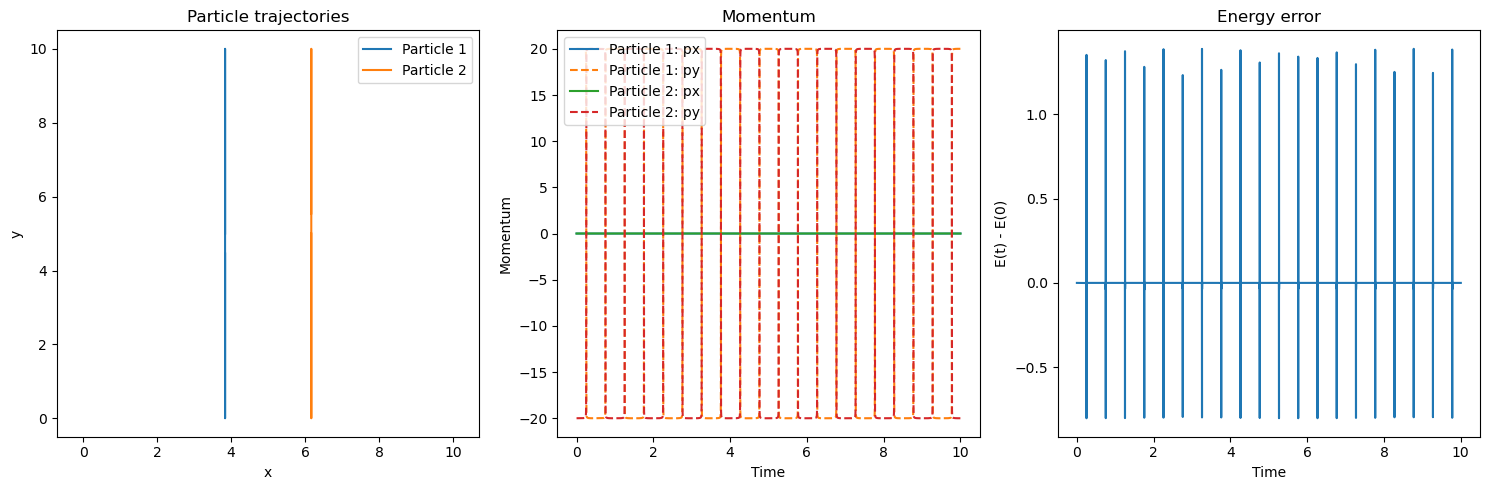


Plotting periodic orbit at E = 361.8676402354


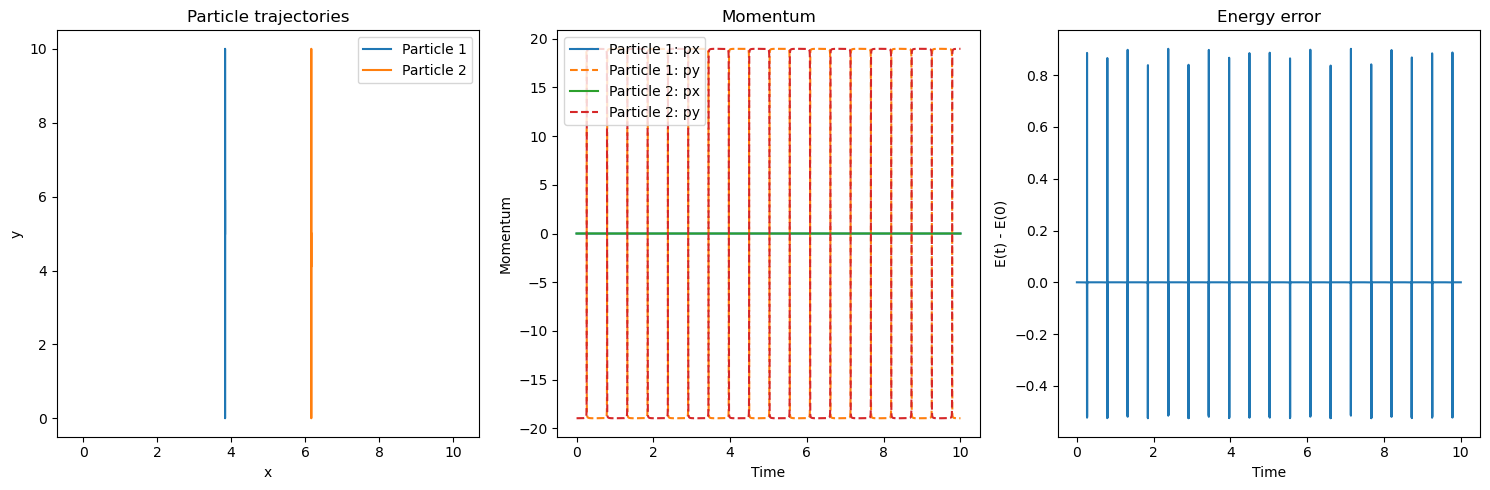


Plotting periodic orbit at E = 321.6601246537


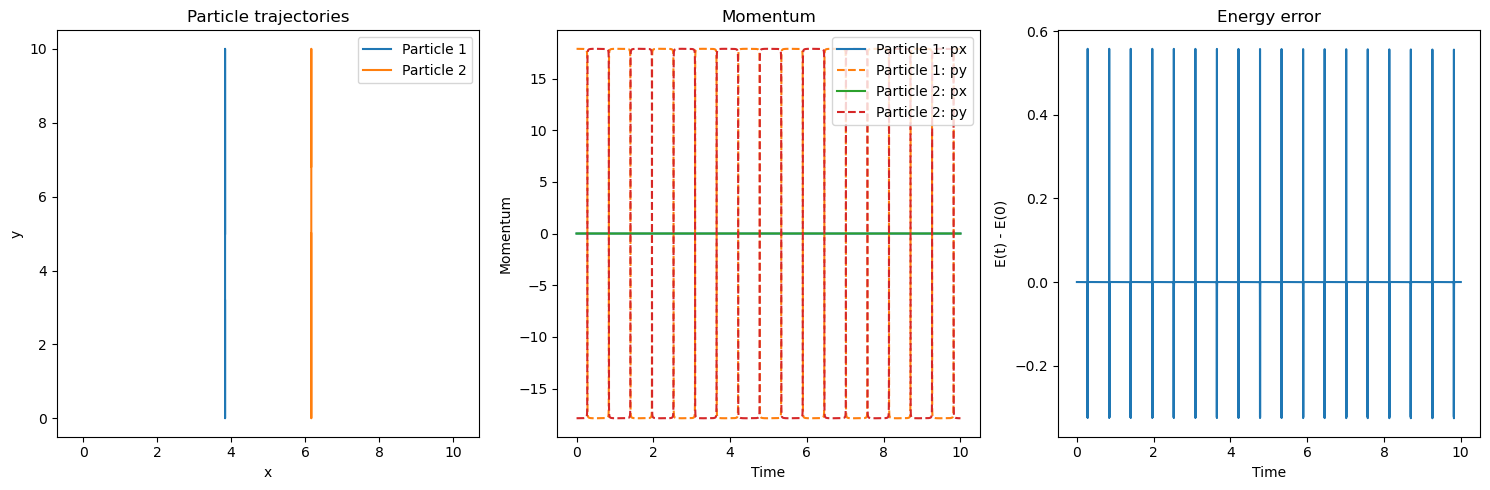


Plotting periodic orbit at E = 281.4526090720


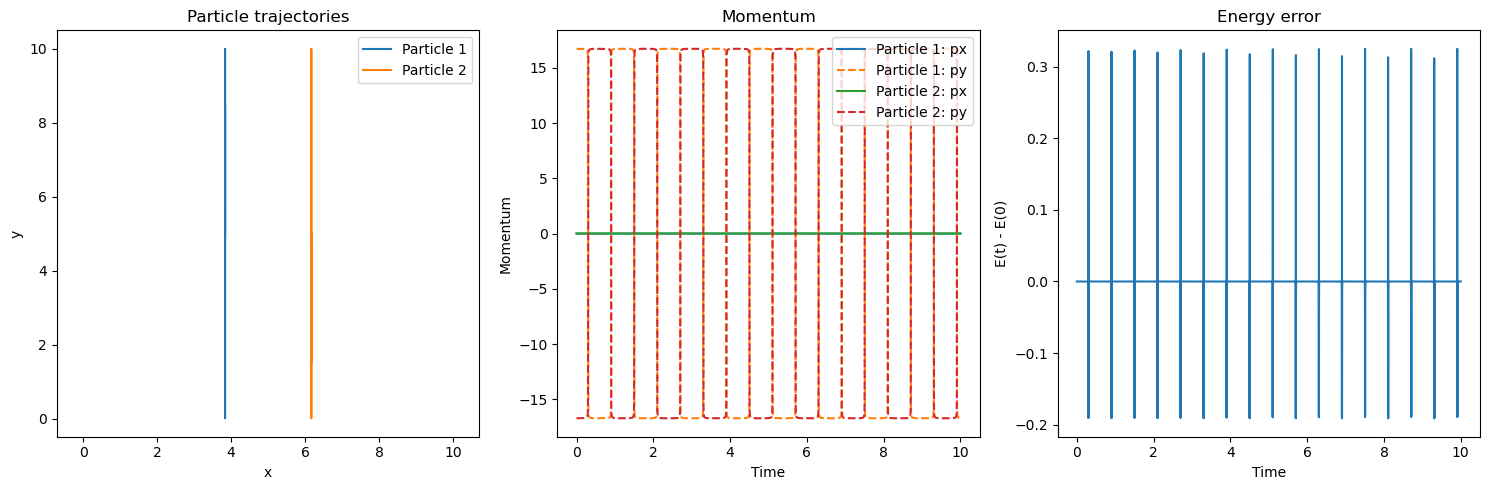


Plotting periodic orbit at E = 241.2450934903


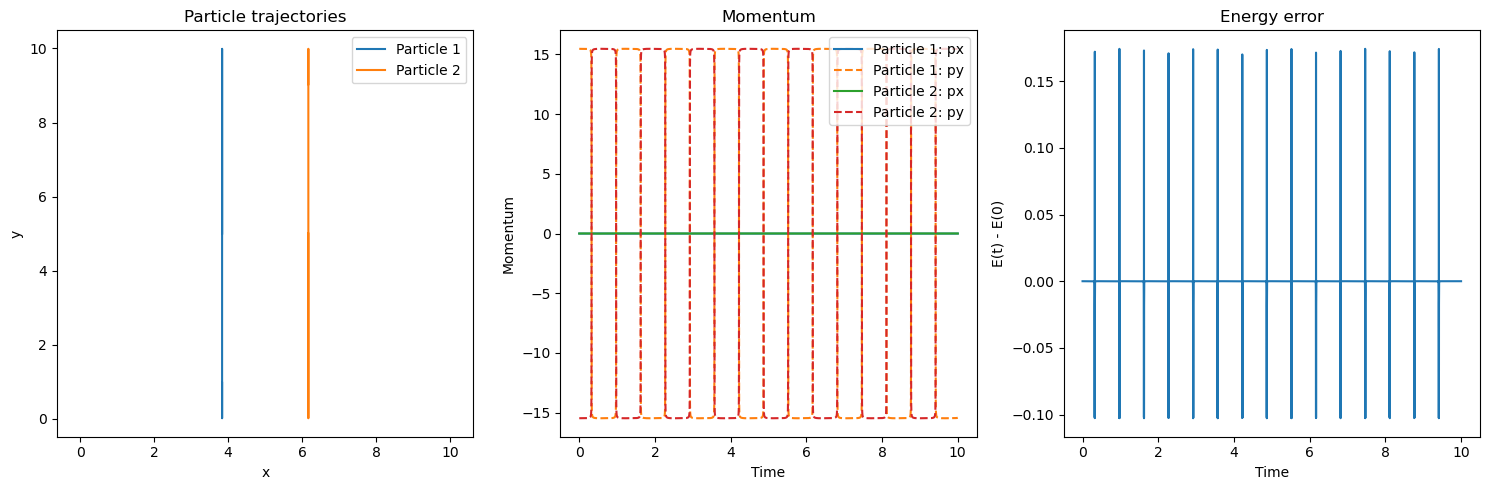


Plotting periodic orbit at E = 201.0375779086


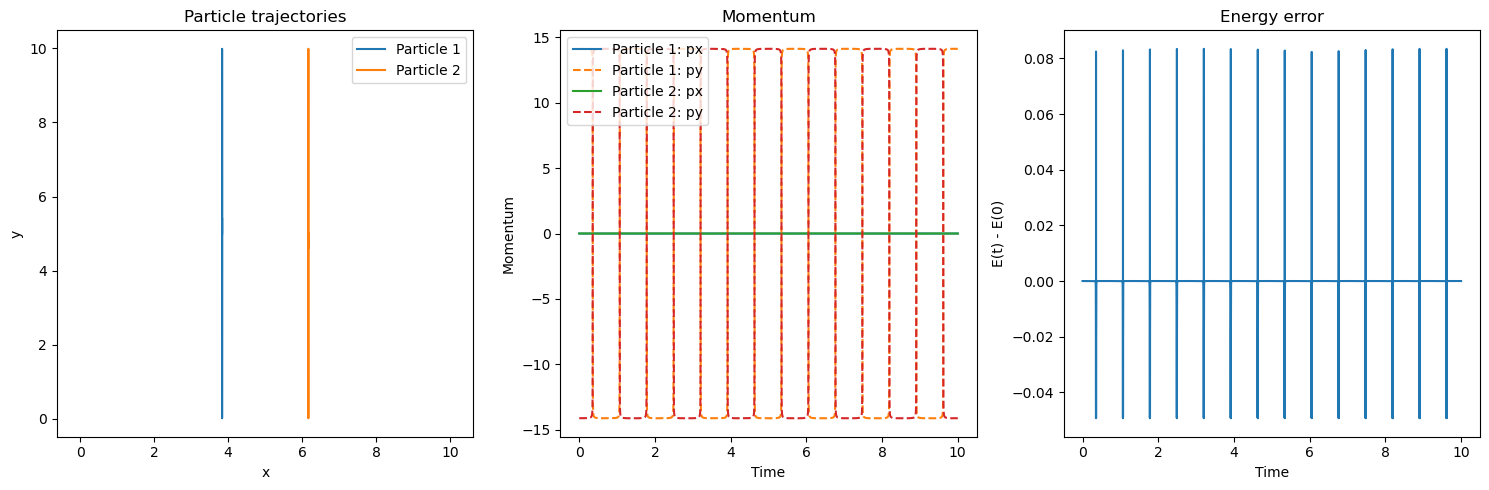


Plotting periodic orbit at E = 160.8300623268


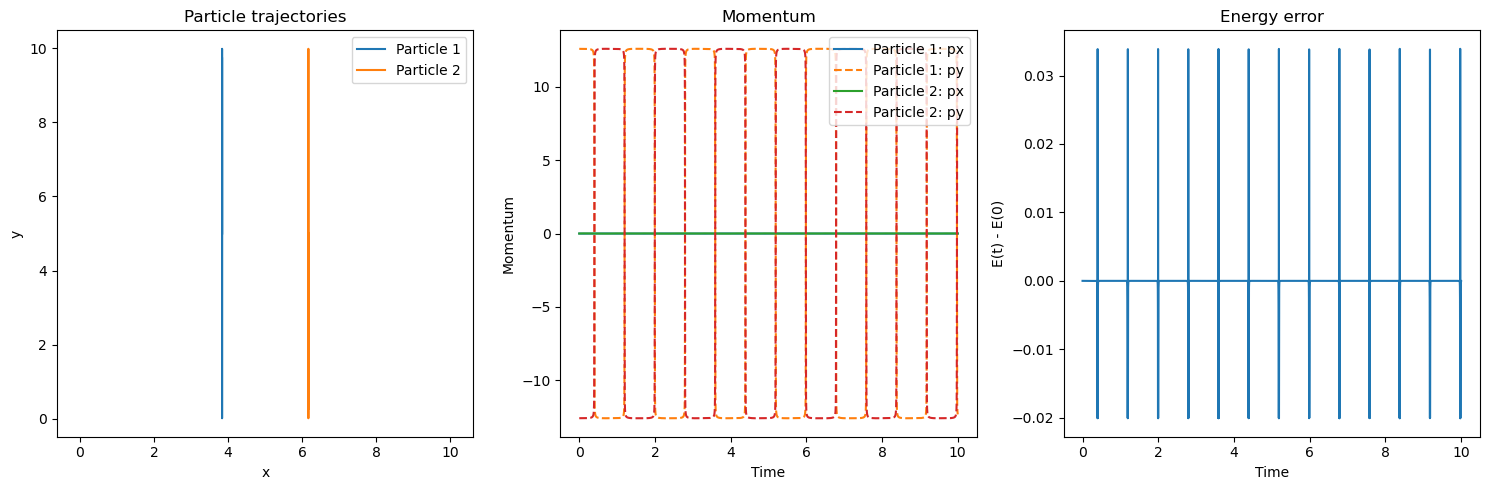


Plotting periodic orbit at E = 120.6225467451


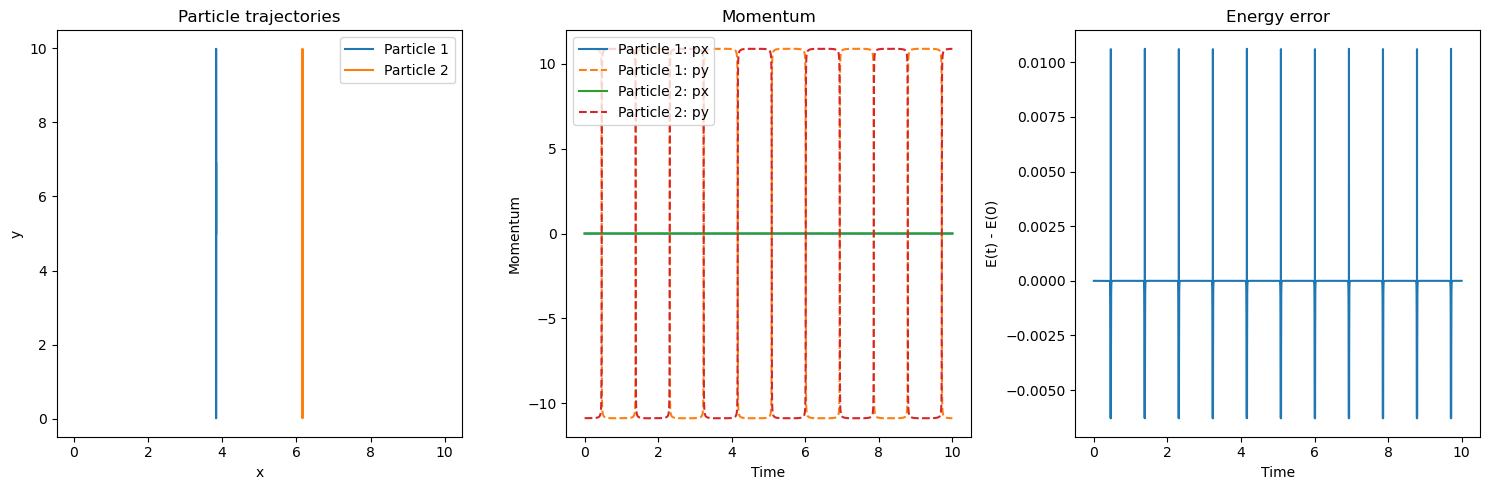


Plotting periodic orbit at E = 80.4150311634


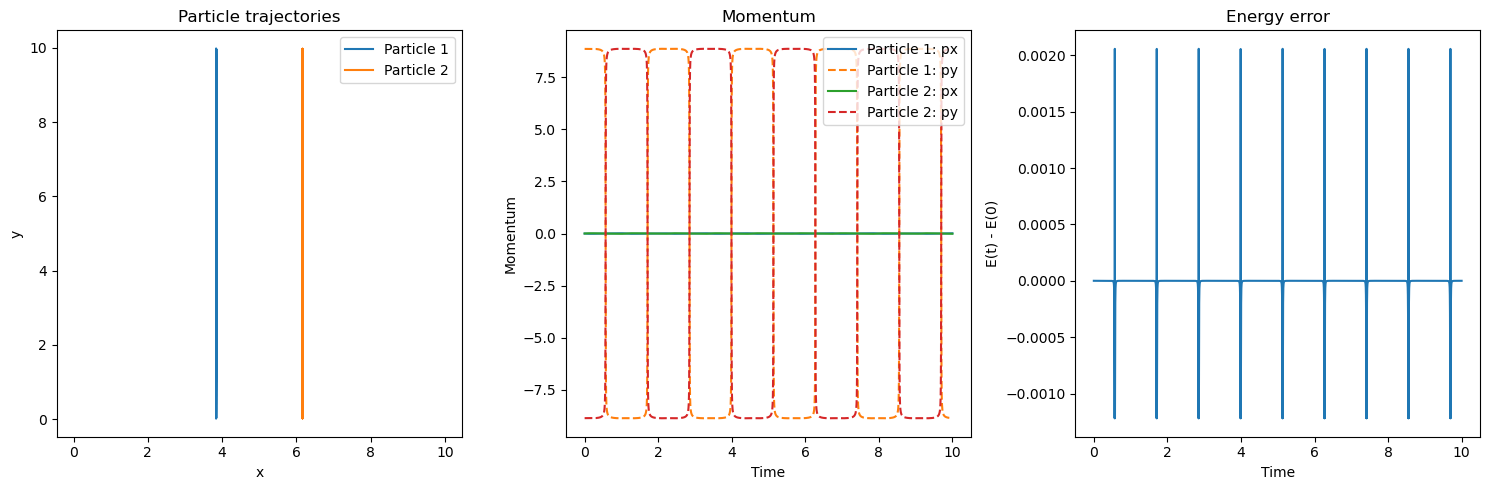


Plotting periodic orbit at E = 40.2075155817


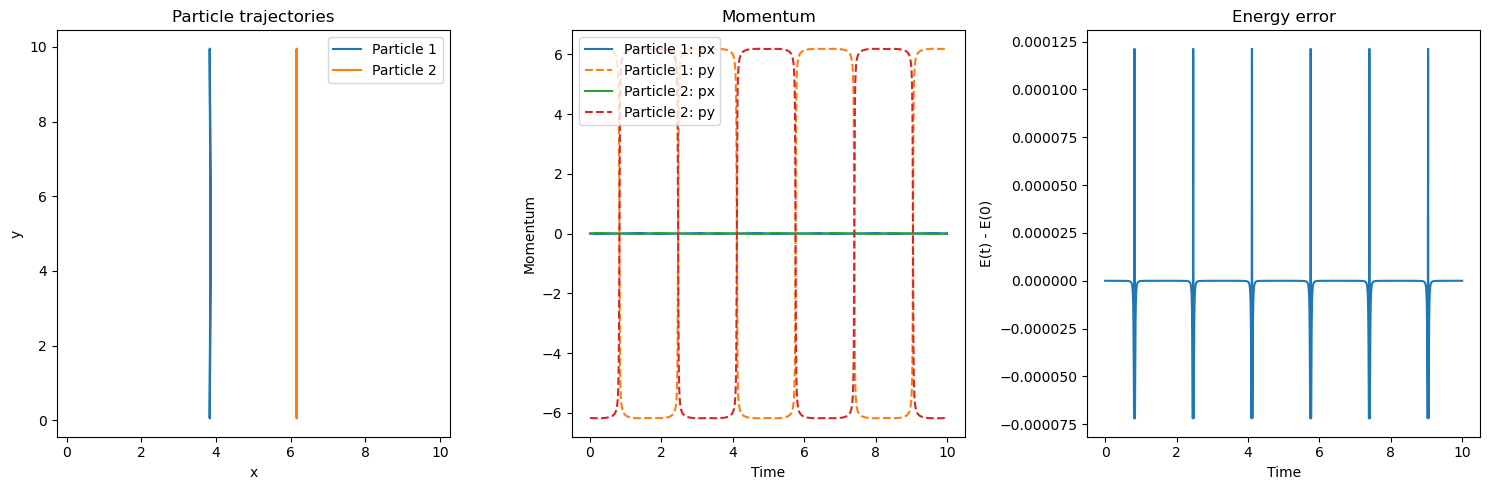


Plotting periodic orbit at E = 20.1037577909


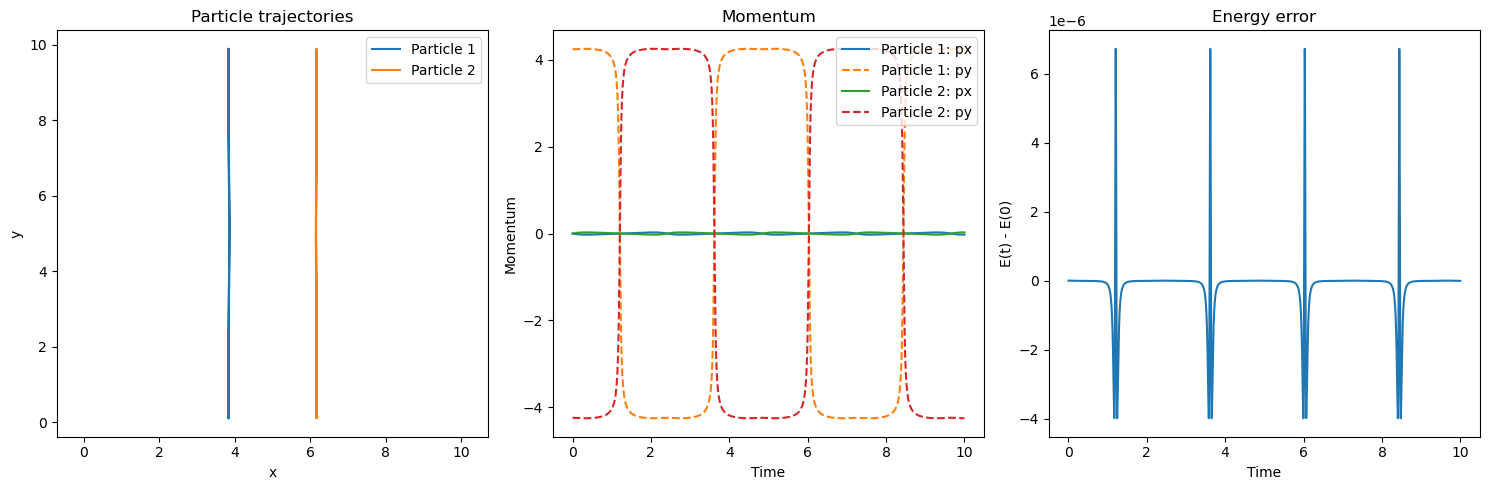


Plotting periodic orbit at E = 4.0207515582


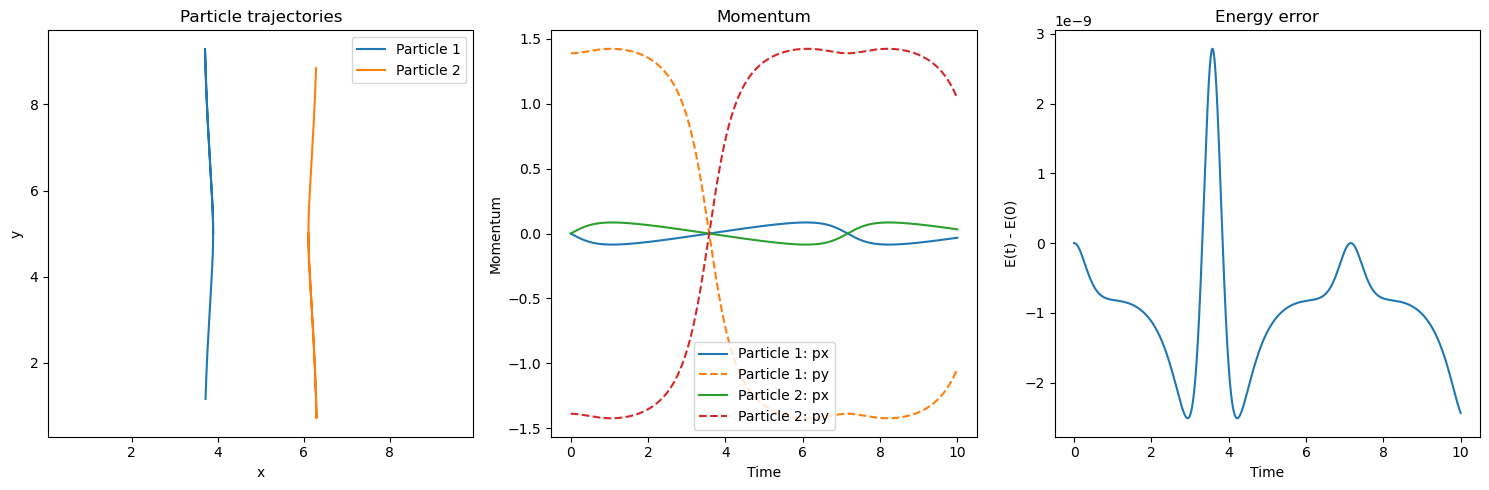

In [371]:
def main():
    """Choose the energy sequence and run the continuation."""
    E0 = total_energy(Q_STAR, P_STAR)

    # Use a 1% step for Newton continuation from high to medium energy.
    # Keeping the continuation step small gives Newton a nearby initial guess.
    # Wider scan: use larger relative steps at high energy, then continue
    # down to single-digit and sub-unit energies.
    # Keeping the ratios explicit makes it easy to change the scan.
    energy_ratios = np.array([
        1.00, 0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60, 0.55,
        0.50, 0.45, 0.40, 0.35, 0.30, 0.25, 0.20, 0.15, 0.10, 0.075,
        0.050, 0.025, 0.010,
    ])
    energies = E0 * energy_ratios
    print("section coordinates:", SECTION_COORDINATES)
    print(f"initial energy: {E0:.10f}")

    return continue_periodic_orbit(energies)


if __name__ == "__main__":
    results = main()
    # Only plot every 10th continuation point (about every 10% in E/E0).
    plot_periodic_trajectories(
        results, h=1e-4, nsteps=100000, plot_every=2,
    )
